# Welcome and Goals

**Goal:** Understand how explanations affect developer trust in LLM-generated code repairs.

By the end of this walkthrough, participants should be able to:
1. Explain why patch correctness alone is not enough for developer adoption.
2. Distinguish between different explanation strategies (baseline, ante-hoc, and post-hoc).
3. Interpret basic quantitative results from an LLM vulnerability repair study (Net Improvement Rate/Bandit Pass Rate).

In [ ]:
%pip install -q bandit
%pip install -q openai

# Motivation - Why explainability matters

Setting the stage, imagine you are a security researcher or developer in industry. You're increasingly working with AI-tools and reviewing AI-generated code. You're presented with a patch for review, it looks plausible but should you merge it?

LLMs can generate code patches, including security fixes, but developers still need to decide whether those patches are safe, correct, maintainable, and worth merging.



> *Would you merge an AI-generated security patch if it passed a static analyzer but gave no explanation?*



In [ ]:
# Create Vulnerable File

%%writefile vulnerable_example.py
import subprocess
import hashlib

password = "super_secret_password"

def run_command(user_input):
    subprocess.call("ls " + user_input, shell=True)

def hash_password(pw):
    return hashlib.md5(pw.encode()).hexdigest()

Overwriting vulnerable_example.py


# Vulnerability Walkthrough

Lets first examine vulnerable Python code and get familiar with our automatic static analysis tool, **Bandit**.

Bandit is a static analysis tool that scans Python code for common security issues. It does not prove that the code is exploitable, but it highlights patterns that deserve closer review.

> When might a developer use Bandit within their workflow to protect against vulnerabilities?

> Are all Bandit outpus to be trusted? Why or why not?

In [ ]:
# Run Bandit
!bandit -r vulnerable_example.py -f json -o bandit_report.json

[main]	INFO	profile include tests: None
[main]	INFO	profile exclude tests: None
[main]	INFO	cli include tests: None
[main]	INFO	cli exclude tests: None
[json]	INFO	JSON output written to file: bandit_report.json


In [ ]:
import json
import pandas as pd
from IPython.display import display, Markdown

# Load Bandit report
with open("bandit_report.json", "r") as f:
    report = json.load(f)

results = report["results"]
totals = report["metrics"]["_totals"]

# Summary table
summary_df = pd.DataFrame([
    {"Metric": "Lines of code scanned", "Value": totals["loc"]},
    {"Metric": "High severity findings", "Value": totals["SEVERITY.HIGH"]},
    {"Metric": "Medium severity findings", "Value": totals["SEVERITY.MEDIUM"]},
    {"Metric": "Low severity findings", "Value": totals["SEVERITY.LOW"]},
    {"Metric": "High confidence findings", "Value": totals["CONFIDENCE.HIGH"]},
    {"Metric": "Medium confidence findings", "Value": totals["CONFIDENCE.MEDIUM"]},
    {"Metric": "Low confidence findings", "Value": totals["CONFIDENCE.LOW"]},
])

display(Markdown("## Bandit Scan Summary"))
display(summary_df)

# Findings table
findings_df = pd.DataFrame([
    {
        "Severity": issue["issue_severity"],
        "Confidence": issue["issue_confidence"],
        "Test ID": issue["test_id"],
        "Issue": issue["issue_text"],
        "File": issue["filename"],
        "Line": issue["line_number"],
        "CWE": f"CWE-{issue['issue_cwe']['id']}",
        "More Info": issue["more_info"],
    }
    for issue in results
])

# Sort the most serious findings first
severity_order = {"HIGH": 3, "MEDIUM": 2, "LOW": 1}
findings_df["Severity Rank"] = findings_df["Severity"].map(severity_order)

findings_df = (
    findings_df
    .sort_values(by=["Severity Rank", "Line"], ascending=[False, True])
    .drop(columns=["Severity Rank"])
)

display(Markdown("## Bandit Findings"))
display(findings_df)

## Bandit Scan Summary

,Metric,Value
0,Lines of code scanned,7
1,High severity findings,2
2,Medium severity findings,0
3,Low severity findings,2
4,High confidence findings,3
5,Medium confidence findings,1
6,Low confidence findings,0


## Bandit Findings

,Severity,Confidence,Test ID,Issue,File,Line,CWE,More Info
2,HIGH,HIGH,B602,"subprocess call with shell=True identified, se...",./vulnerable_example.py,7,CWE-78,https://bandit.readthedocs.io/en/1.9.4/plugins...
3,HIGH,HIGH,B324,Use of weak MD5 hash for security. Consider us...,./vulnerable_example.py,10,CWE-327,https://bandit.readthedocs.io/en/1.9.4/plugins...
0,LOW,HIGH,B404,Consider possible security implications associ...,./vulnerable_example.py,1,CWE-78,https://bandit.readthedocs.io/en/1.9.4/blackli...
1,LOW,MEDIUM,B105,Possible hardcoded password: 'super_secret_pas...,./vulnerable_example.py,4,CWE-259,https://bandit.readthedocs.io/en/1.9.4/plugins...


## What do these Bandit findings mean?

### B602: `subprocess` with `shell=True`

This is one of the most serious findings in the example.

The code builds a shell command using user input:

`subprocess.call("ls " + user_input, shell=True)`

Because the command is created by joining strings together, a malicious user may be able to change the command that gets executed. This is called command injection.

A safer approach is to avoid `shell=True` and pass arguments as a list, such as:

`subprocess.call(["ls", user_input])`

Even then, user input should still be validated.

### B324: Weak MD5 hashing

The code uses MD5 to hash a password:

`hashlib.md5(pw.encode()).hexdigest()`

MD5 is no longer considered secure for password storage or other security-sensitive hashing. It is fast, old, and vulnerable to attacks.

For passwords, use a password hashing algorithm such as bcrypt, scrypt, or Argon2. These are designed to make password cracking much harder.

### B404: Importing `subprocess`

The `subprocess` module lets Python run operating system commands. Importing it is not automatically unsafe, but it can become dangerous if user input is passed into a command.

In this example, Bandit flags the import because `subprocess` is often associated with command execution risks.

### B105: Hardcoded password

The code contains a password directly in the source file:

`password = "super_secret_password"`

This is risky because source code is often committed to Git, shared with other developers, copied into examples, or deployed across environments. Secrets should not live directly in code.

A safer approach is to use environment variables, configuration files excluded from version control, or a secrets manager.

# Prompting Methods - Comparing Explanation Styles

In this next section, we will get exposed to three different explanation styles geared towards working with LLMs.

We will examine a simplistic **baseline** approach, which just instructs the LLM to generate the patch.

Next we will examine an **"ante-hoc"** approach, which generates the explanation + patched code in a **single inference step**.

Finally, we still examine a **"post-hoc"** method, which generates the patched code first, and then retroactively generates an explanation.

In [ ]:
# Baseline

BASELINE_PROMPT_SYSTEM = '''
You are a Python security expert. You will receive vulnerable Python code. Produce a minimal, correct, and safe patched Python file that fixes the vulnerability and preserves original behavior where reasonable.
Output only the patched Python code bytes — no preamble, no explanation, no filenames, no backticks.
If the request would enable exploitation or is disallowed, output a single-line Python comment beginning with # REFUSE: and a brief reason.'''

BASELINE_PROMPT_USER='''
Take the following vulnerable code snippet and output patched Python-code only. If your fix requires external config or permissions, include those requirements as inline comments inside the code only. Do not output anything else.

Vulnerable Code:
{vulnerable_code}

Patch:
```python
# Full runnable patched Python file
<patched code here>
'''

In [ ]:
# Ante-Hoc

ANTE_HOC_PROMPT_SYSTEM = '''
You are a Python security engineer focused on explainable patching.
Do NOT detect vulnerabilities — assume the CWE IDs provided are correct.
Focus only on evidence, reasoning, and producing a safe patch that preserves the original behavior wherever reasonable.'''

ANTE_HOC_PROMPT_USER='''
Here is the vulnerable code and the CWE IDs:

vulnerable_code: """{vulnerable_code}"""
cwe_ids: {cwe_ids}   # e.g., CWE-78 CWE-94

Produce output in exactly the following format (nothing else):

### CWE Blocks
For each CWE in {cwe_ids}, provide:

Evidence:
- [E1] Relevant code lines: <start–end>
- [E2] Language pattern: <e.g., use of eval / subprocess>
- [E3] Violated principle: <e.g., lack of input validation>

Explanation:
- Step-by-step reasoning linking evidence to how the vulnerability is mitigated (3–6 short bullets).

Patch:
```python
# Full runnable patched Python file
<patched code here>

Justification:
1–3 sentences connecting each patch to the evidence.

RULES:
Prioritize interpretability and evidence linkage.
Minimal edits: preserve original behavior wherever reasonable.
If the fix would enable exploitation or violates policy, output exactly: REFUSE: <brief reason>
'''

In [ ]:
# Post-Hoc

POST_HOC_PROMPT_1_SYSTEM = '''
You are a Python security expert. You will receive vulnerable Python code. Produce a minimal, correct, and safe patched Python file that fixes the vulnerability and preserves original behavior where reasonable.
Output only the patched Python code bytes. no preamble, no explanation, no filenames, no backticks.
If the request would enable exploitation or is disallowed, output a single-line Python comment beginning with # REFUSE: and a brief reason.
'''
POST_HOC_PROMPT_1_USER='''
Take the following vulnerable code snippet and output patched Python-code only. If your fix requires external config or permissions, include those requirements as inline comments inside the code only. Do not output anything else.

Vulnerable Code:
{vulnerable_code}

Patch:
```python
# Full runnable patched Python file
<patched code here>
'''

POST_HOC_PROMPT_2_SYSTEM = '''
You are an Explainable AI reviewer and Python security engineer.
Do NOT detect vulnerabilities assume the CWE IDs provided are correct.


Task: Compare the original vulnerable code and the patched code produced in Stage 1, and produce a faithful, human-readable Explanation Report that follows XAI best practices.


Requirements (must be followed exactly):
- Faithfulness: every claim must map to concrete code lines in Original or Patched code.
- Completeness: cover every modification and every provided CWE.
- Counterfactual (local fidelity) checks for each modification, explicitly answer:
  "If this change were applied, would the vulnerability be removed? Yes/No + 1 sentence."
- Anchor-style rule: where relevant, include one concise "If <pattern> then <risk>" sentence per CWE.
- Confidence / limitations: include High/Medium/Low + a one-line limitation note per modification.
- Engineering outcomes: for each CWE/modification include:
 - Expected Bandit effect: Drop / NoChange / Unknown
 - Expected unit-test/runtime impact: Preserved / MayChange / Unknown
- Minimal edits & behavior preservation: note if behavior is preserved or exactly what changed.
- Output discipline: produce the Explanation Report in the exact format below and no extra text.

#Explanation Report
For each CWE in {cwe_ids}:
- Evidence:
  - Relevant lines in ORIGINAL: <start–end>
  - Relevant lines in PATCHED: <start–end> (if line numbers shifted, use approximate region and mention you mapped lines)
  - Pattern mitigated: <short>
- Reasoning chain (3–6 bullets):
  1. <bullet mapping evidence → why vulnerable>
  2. <bullet mapping change → how it mitigates>
  3. <counterfactual check: "If applied, would vulnerability be removed? Yes/No + 1 sentence">
  4–6. (optional additional supporting bullets)
- Anchor-style rule (if applicable): "If <pattern> then <risk>"
- Functional impact: <behavior preserved / modified — describe precise change if modified>
- Confidence / Limitation: <High/Medium/Low + 1-line limitation>
- Expected Bandit effect: <Drop/NoChange/Unknown>
- Expected unit-test/runtime impact: <Preserved/MayChange/Unknown>

Output format exactly:

#Patched Code
```python
<patched code here>
'''
POST_HOC_PROMPT_2_USER='''
Original code: """ {vulnerable_code} """
Patched code: """ {previous_output} """
CWE IDs: {cwe_ids}
Now produce the Explanation Report in the exact format required by the system prompt.
'''

In [ ]:
# Import and Setup OpenAI API
import os
import json
import pandas as pd
from pathlib import Path
from openai import OpenAI
from IPython.display import display, Markdown

# Setup OpenAI Client
API_KEY = ""
os.environ["OPENAI_API_KEY"] = API_KEY
client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])
print("OpenAI client is ready.")

# Load Vulnerable Code and Bandit Report
with open("vulnerable_example.py", "r") as f:
    vulnerable_code = f.read()

with open("bandit_report.json", "r") as f:
    bandit_report = json.load(f)

bandit_findings = bandit_report["results"]

print("Loaded vulnerable code.")
print(f"Loaded {len(bandit_findings)} Bandit findings.")

# Set Model and Output
MODEL_NAME = "gpt-4.1-mini"

OpenAI client is ready.
Loaded vulnerable code.
Loaded 4 Bandit findings.


In [ ]:
# Setup Output Folder and Helper Functions
OUTPUT_DIR = Path("generated_method_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


def save_text(path, text):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8")


def call_model(system_prompt, user_prompt):
    response = client.responses.create(
        model=MODEL_NAME,
        instructions=system_prompt,
        input=user_prompt,
    )
    return response.output_text


def strip_markdown_code_fence(text):
    """
    If the model returns code inside a markdown code block,
    this tries to extract the code only.
    """
    text = text.strip()

    if text.startswith("```"):
        lines = text.splitlines()

        # Remove opening fence
        if lines and lines[0].startswith("```"):
            lines = lines[1:]

        # Remove closing fence
        if lines and lines[-1].startswith("```"):
            lines = lines[:-1]

        return "\n".join(lines).strip()

    return text


def make_base_context():
    """
    Shared context for all repair methods.
    """
    return f"""
Original vulnerable code:

{vulnerable_code}

Bandit findings:

{json.dumps(bandit_findings, indent=2)}
""".strip()


def make_full_context(generated_patch=None):
    """
    Shared context plus an optional generated patch.

    The generated patch is only needed for the second post-hoc stage.
    """
    context = make_base_context()

    if generated_patch is not None:
        context += f"""

Generated repaired code from stage 1:

{generated_patch}
"""

    return context.strip()


def make_prompt_variables(generated_patch=None):
    """
    Variables that can be injected into prompt templates.

    Your prompt templates may use either:
    - {base_context}
    - {full_context}
    - {vulnerable_code}
    - {bandit_findings}
    - {bandit_findings_json}
    - {generated_patch}

    Double braces also work:
    - {{base_context}}
    - {{generated_patch}}
    """
    bandit_findings_json = json.dumps(bandit_findings, indent=2)

    return {
        "base_context": make_base_context(),
        "full_context": make_full_context(generated_patch),
        "vulnerable_code": vulnerable_code,
        "bandit_findings": bandit_findings_json,
        "bandit_findings_json": bandit_findings_json,
        "generated_patch": generated_patch or "",
        "posthoc_patch": generated_patch or "",
    }


def inject_prompt_variables(prompt_template, variables):
    """
    Injects known variables into a prompt template.

    This uses simple string replacement instead of .format(),
    so literal braces in examples or JSON will not break the prompt.
    """
    rendered_prompt = str(prompt_template)

    for name, value in variables.items():
        rendered_prompt = rendered_prompt.replace(f"{{{name}}}", str(value))
        rendered_prompt = rendered_prompt.replace(f"{{{{{name}}}}}", str(value))

    return rendered_prompt


def prompt_has_context_placeholder(prompt_template):
    """
    Checks whether the user prompt already includes one of the shared context placeholders.
    """
    prompt_text = str(prompt_template)

    context_placeholders = [
        "{base_context}",
        "{{base_context}}",
        "{full_context}",
        "{{full_context}}",
        "{vulnerable_code}",
        "{{vulnerable_code}}",
        "{bandit_findings}",
        "{{bandit_findings}}",
        "{bandit_findings_json}",
        "{{bandit_findings_json}}",
    ]

    return any(placeholder in prompt_text for placeholder in context_placeholders)


def prompt_has_patch_placeholder(prompt_template):
    """
    Checks whether the prompt already includes the generated patch placeholder.
    """
    prompt_text = str(prompt_template)

    patch_placeholders = [
        "{generated_patch}",
        "{{generated_patch}}",
        "{posthoc_patch}",
        "{{posthoc_patch}}",
        "{full_context}",
        "{{full_context}}",
    ]

    return any(placeholder in prompt_text for placeholder in patch_placeholders)


def prepare_user_prompt(user_prompt_template, generated_patch=None, append_context_if_missing=True):
    """
    Renders a user prompt and ensures the needed context is included.

    If the prompt template includes placeholders, they are replaced.
    If the prompt template does not include context placeholders, the base context is appended.
    If generated_patch is provided and no patch placeholder is present, the generated patch is appended.
    """
    variables = make_prompt_variables(generated_patch=generated_patch)

    rendered_prompt = inject_prompt_variables(
        prompt_template=user_prompt_template,
        variables=variables,
    )

    if append_context_if_missing and not prompt_has_context_placeholder(user_prompt_template):
        rendered_prompt += "\n\n" + variables["base_context"]

    if generated_patch is not None and not prompt_has_patch_placeholder(user_prompt_template):
        rendered_prompt += f"""

Generated repaired code from stage 1:

{generated_patch}
"""

    return rendered_prompt.strip()


def prepare_system_prompt(system_prompt_template, generated_patch=None):
    """
    Renders a system prompt.

    Context is not automatically appended to the system prompt.
    This only replaces placeholders if you intentionally include them.
    """
    variables = make_prompt_variables(generated_patch=generated_patch)

    return inject_prompt_variables(
        prompt_template=system_prompt_template,
        variables=variables,
    ).strip()


def run_stage(
    method,
    stage_name,
    system_prompt,
    user_prompt,
    output_extension="md",
    generated_patch=None,
    append_context_if_missing=True,
):
    """
    Runs one model call and saves:
    1. The rendered system prompt
    2. The rendered user prompt
    3. The model output
    """
    stage_dir = OUTPUT_DIR / method / stage_name
    stage_dir.mkdir(parents=True, exist_ok=True)

    rendered_system_prompt = prepare_system_prompt(
        system_prompt_template=system_prompt,
        generated_patch=generated_patch,
    )

    rendered_user_prompt = prepare_user_prompt(
        user_prompt_template=user_prompt,
        generated_patch=generated_patch,
        append_context_if_missing=append_context_if_missing,
    )

    system_prompt_path = stage_dir / "system_prompt.txt"
    user_prompt_path = stage_dir / "user_prompt.txt"
    output_path = stage_dir / f"output.{output_extension}"

    save_text(system_prompt_path, rendered_system_prompt)
    save_text(user_prompt_path, rendered_user_prompt)

    output = call_model(
        system_prompt=rendered_system_prompt,
        user_prompt=rendered_user_prompt,
    )

    save_text(output_path, output)

    return {
        "method": method,
        "stage": stage_name,
        "system_prompt_file": str(system_prompt_path),
        "user_prompt_file": str(user_prompt_path),
        "output_file": str(output_path),
        "output": output,
    }

In [ ]:
# Run Methods
all_results = []

# ------------------------------------------------------------
# Method 1: PTC, baseline patch-only
# Uses BASELINE_PROMPT_SYSTEM and BASELINE_PROMPT_USER.
# The vulnerable code and Bandit findings are injected automatically.
# ------------------------------------------------------------

ptc_result = run_stage(
    method="PTC",
    stage_name="stage_1_patch",
    system_prompt=BASELINE_PROMPT_SYSTEM,
    user_prompt=BASELINE_PROMPT_USER,
    output_extension="py",
)

ptc_patch = strip_markdown_code_fence(ptc_result["output"])
save_text(OUTPUT_DIR / "PTC" / "stage_1_patch" / "patch.py", ptc_patch)

all_results.append(ptc_result)


# ------------------------------------------------------------
# Method 2: EXP, ante-hoc patch plus explanation
# Uses ANTE_HOC_PROMPT_SYSTEM and ANTE_HOC_PROMPT_USER.
# The vulnerable code and Bandit findings are injected automatically.
# ------------------------------------------------------------

exp_result = run_stage(
    method="EXP",
    stage_name="stage_1_patch_and_explanation",
    system_prompt=ANTE_HOC_PROMPT_SYSTEM,
    user_prompt=ANTE_HOC_PROMPT_USER,
    output_extension="md",
)

all_results.append(exp_result)


# ------------------------------------------------------------
# Method 3: PTC-EXP, post-hoc two-stage method
# Stage 1: Generate patch
# Uses POST_HOC_PROMPT_1_SYSTEM and POST_HOC_PROMPT_1_USER.
# The vulnerable code and Bandit findings are injected automatically.
# ------------------------------------------------------------

posthoc_patch_result = run_stage(
    method="PTC-EXP",
    stage_name="stage_1_patch",
    system_prompt=POST_HOC_PROMPT_1_SYSTEM,
    user_prompt=POST_HOC_PROMPT_1_USER,
    output_extension="py",
)

posthoc_patch = strip_markdown_code_fence(posthoc_patch_result["output"])
save_text(OUTPUT_DIR / "PTC-EXP" / "stage_1_patch" / "patch.py", posthoc_patch)

all_results.append(posthoc_patch_result)


# ------------------------------------------------------------
# Method 3: PTC-EXP, post-hoc two-stage method
# Stage 2: Explain generated patch
# Uses POST_HOC_PROMPT_2_SYSTEM and POST_HOC_PROMPT_2_USER.
# The original context and the stage 1 patch are injected automatically.
# ------------------------------------------------------------

posthoc_explanation_result = run_stage(
    method="PTC-EXP",
    stage_name="stage_2_explanation",
    system_prompt=POST_HOC_PROMPT_2_SYSTEM,
    user_prompt=POST_HOC_PROMPT_2_USER,
    output_extension="md",
    generated_patch=posthoc_patch,
)

all_results.append(posthoc_explanation_result)


print("Done. All method inputs and outputs have been saved.")

Done. All method inputs and outputs have been saved.


In [ ]:
# -----------------------------
# Configuration
# -----------------------------

import subprocess
from IPython.display import display, Markdown, HTML

OUTPUTS_DIR = Path("generated_method_outputs")
ORIGINAL_FILE = Path("vulnerable_example.py")

# Maps folder name -> human-readable stage label
METHOD_LABELS = {
    "PTC":     "Baseline (PTC)",
    "EXP":     "Ante-Hoc (EXP)",
    "PTC-EXP": "Post-Hoc (PTC-EXP)",
}

# Display order for the three stages
METHOD_ORDER = {label: i for i, label in enumerate(METHOD_LABELS.values())}

# -----------------------------
# Helpers
# -----------------------------

def infer_method_label(py_file: Path) -> str:
    """
    Returns the human-readable stage label for a patched file based on
    its parent folder name (PTC / EXP / PTC-EXP).
    Falls back to the raw folder name if not recognised.
    """
    folder = py_file.parent.parent.name   # e.g. generated_method_outputs/PTC/stage_1_patch/patch.py
    return METHOD_LABELS.get(folder, folder)


def extract_python_from_markdown(md_text: str) -> str | None:
    """
    Extracts the first Python code block from a markdown string.

    Looks for ```python ... ``` first; falls back to any ``` ... ``` block.
    Returns the extracted code as a string, or None if no block is found.
    """
    import re

    # Try ```python ... ``` first
    match = re.search(r"```python\s*\n(.*?)```", md_text, re.DOTALL)
    if match:
        return match.group(1).strip()

    # Fall back to any fenced code block
    match = re.search(r"```[^\n]*\n(.*?)```", md_text, re.DOTALL)
    if match:
        return match.group(1).strip()

    return None


def ensure_patch_for_method(method_folder: str) -> Path | None:
    """
    Returns a Path to a runnable patch.py for the given method folder name.

    - PTC / PTC-EXP:  patch.py already exists under stage_1_patch/.
    - EXP:            output.md contains an embedded code block; extract it
                      and write patch.py next to the .md file so Bandit can
                      analyse it.

    Returns None if the required source file cannot be found.
    """
    method_dir = OUTPUTS_DIR / method_folder

    if not method_dir.exists():
        return None

    # PTC and PTC-EXP write patch.py directly
    patch_py = method_dir / "stage_1_patch" / "patch.py"
    if patch_py.exists():
        return patch_py

    # EXP produces output.md — parse out the embedded Python code block
    output_md = method_dir / "stage_1_patch_and_explanation" / "output.md"
    if output_md.exists():
        derived_patch = output_md.with_name("patch.py")

        # Only re-extract if not already done (or if .md is newer)
        if not derived_patch.exists() or output_md.stat().st_mtime > derived_patch.stat().st_mtime:
            md_text = output_md.read_text(encoding="utf-8")
            code = extract_python_from_markdown(md_text)

            if code is None:
                print(f"  WARNING: No Python code block found in {output_md}")
                return None

            derived_patch.write_text(code, encoding="utf-8")
            print(f"  Extracted patch from {output_md.name} → {derived_patch.name}")

        return derived_patch

    return None


def run_bandit(py_file: Path) -> dict:
    """
    Runs Bandit on a single Python file and returns the parsed JSON report.
    Bandit returns non-zero when issues are found, so we do not use check=True.
    """
    report_path = py_file.with_suffix(".bandit.json")

    cmd = [
        "bandit",
        "-r", str(py_file),
        "-f", "json",
        "-o", str(report_path),
        "-q",
    ]

    subprocess.run(cmd, capture_output=True, text=True)

    if not report_path.exists():
        return {"results": [], "metrics": {}}

    with open(report_path, "r", encoding="utf-8") as f:
        return json.load(f)


def summarize_bandit_report(py_file: Path, report: dict, method_label: str) -> dict:
    results = report.get("results", [])

    severity_counts   = {"LOW": 0, "MEDIUM": 0, "HIGH": 0}
    confidence_counts = {"LOW": 0, "MEDIUM": 0, "HIGH": 0}
    test_ids = []

    for issue in results:
        sev  = issue.get("issue_severity",   "UNKNOWN")
        conf = issue.get("issue_confidence", "UNKNOWN")
        tid  = issue.get("test_id",          "UNKNOWN")
        if sev  in severity_counts:   severity_counts[sev]   += 1
        if conf in confidence_counts: confidence_counts[conf] += 1
        test_ids.append(tid)

    return {
        "Stage":            method_label,
        "File":             str(py_file),
        "Vulnerabilities":  len(results),
        "High":             severity_counts["HIGH"],
        "Medium":           severity_counts["MEDIUM"],
        "Low":              severity_counts["LOW"],
        "Low Confidence":   confidence_counts["LOW"],
        "Med Confidence":   confidence_counts["MEDIUM"],
        "High Confidence":  confidence_counts["HIGH"],
        "CWEs":             ", ".join(sorted(set(test_ids))),
    }


# -----------------------------
# Validate paths
# -----------------------------

if not ORIGINAL_FILE.exists():
    raise FileNotFoundError(
        f"Could not find original file: {ORIGINAL_FILE}. "
        "Update ORIGINAL_FILE to point to your vulnerable input file."
    )

if not OUTPUTS_DIR.exists():
    raise FileNotFoundError(
        f"Could not find generated outputs folder: {OUTPUTS_DIR}. "
        "Update OUTPUTS_DIR if your output folder name is different."
    )

# -----------------------------
# Run Bandit on original file
# -----------------------------

original_report  = run_bandit(ORIGINAL_FILE)
original_results = original_report.get("results", [])
original_vulns   = len(original_results)

display(Markdown("## Bandit Vulnerability Analysis"))
display(Markdown(f"**Original file:** `{ORIGINAL_FILE}`  \n"
                 f"**Vulnerabilities in original:** {original_vulns}"))

# -----------------------------
# Collect one patch file per method
# (EXP: extracted from output.md; others: patch.py written by run_stage)
# -----------------------------

display(Markdown("**Collecting patch files…**"))
patch_files = []
for folder_name in METHOD_LABELS:          # PTC, EXP, PTC-EXP — in definition order
    patch_path = ensure_patch_for_method(folder_name)
    if patch_path:
        patch_files.append(patch_path)
        print(f"  ✓ {METHOD_LABELS[folder_name]:25s}  →  {patch_path}")
    else:
        print(f"  ✗ {METHOD_LABELS[folder_name]:25s}  →  not found (method may not have been run yet)")

if not patch_files:
    display(Markdown(f"> No patch files found under `{OUTPUTS_DIR}`. Run the earlier cells first."))
else:
    rows = []

    for py_file in patch_files:
        label  = infer_method_label(py_file)
        report = run_bandit(py_file)
        summary = summarize_bandit_report(py_file, report, label)

        patched_vulns        = summary["Vulnerabilities"]
        net_improvement      = original_vulns - patched_vulns
        net_improvement_pct  = (net_improvement / original_vulns * 100) if original_vulns > 0 else 0.0

        summary["Original Vulns"]    = original_vulns
        summary["Vulns Removed"]     = net_improvement
        summary["Improvement %"]     = round(net_improvement_pct, 1)

        rows.append(summary)

    df = pd.DataFrame(rows)

    # Sort by canonical stage order, unknown stages go last
    df["_order"] = df["Stage"].map(METHOD_ORDER).fillna(99).astype(int)
    df = df.sort_values("_order").drop(columns=["_order"]).reset_index(drop=True)

    # ------------------------------------------------------------------
    # File-level table
    # ------------------------------------------------------------------

    display(Markdown("### Per-File Results"))

    file_cols = ["Stage", "File", "Original Vulns", "Vulnerabilities", "Vulns Removed",
                 "Improvement %", "High", "Medium", "Low", "CWEs"]
    display(
        df[file_cols]
        .style
        .set_caption("Bandit results for each patched file")
        .format({"Improvement %": "{:.1f}%"})
        .bar(subset=["Improvement %"], color="#4caf50", vmin=0, vmax=100)
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "1em"), ("font-weight", "bold"), ("text-align", "left")]},
            {"selector": "th",
             "props": [("background-color", "#1a237e"), ("color", "white"),
                       ("text-align", "center"), ("padding", "6px 10px")]},
            {"selector": "td",
             "props": [("text-align", "center"), ("padding", "5px 10px")]},
        ])
        .hide(axis="index")
    )

    # ------------------------------------------------------------------
    # Method-level aggregate summary
    # ------------------------------------------------------------------

    agg_df = (
        df
        .groupby("Stage", sort=False)
        .agg(
            Files=("File", "count"),
            Avg_Vulns=("Vulnerabilities", "mean"),
            Min_Vulns=("Vulnerabilities", "min"),
            Max_Vulns=("Vulnerabilities", "max"),
            Avg_Removed=("Vulns Removed", "mean"),
            Avg_Improvement_Pct=("Improvement %", "mean"),
            Total_High=("High", "sum"),
            Total_Medium=("Medium", "sum"),
            Total_Low=("Low", "sum"),
        )
        .rename(columns={
            "Files":               "Files Evaluated",
            "Avg_Vulns":           "Avg Vulns",
            "Min_Vulns":           "Min Vulns",
            "Max_Vulns":           "Max Vulns",
            "Avg_Removed":         "Avg Removed",
            "Avg_Improvement_Pct": "Avg Improvement %",
            "Total_High":          "Total High",
            "Total_Medium":        "Total Medium",
            "Total_Low":           "Total Low",
        })
        .reset_index()
    )

    # Preserve stage display order
    agg_df["_order"] = agg_df["Stage"].map(METHOD_ORDER).fillna(99).astype(int)
    agg_df = agg_df.sort_values("_order").drop(columns=["_order"]).reset_index(drop=True)

    display(Markdown("### Summary by Stage"))
    display(
        agg_df
        .style
        .set_caption("Aggregate Bandit results — Baseline (PTC) · Ante-Hoc (EXP) · Post-Hoc (PTC-EXP)")
        .format({
            "Avg Vulns":        "{:.1f}",
            "Avg Removed":      "{:.1f}",
            "Avg Improvement %": "{:.1f}%",
        })
        .bar(subset=["Avg Improvement %"], color="#4caf50", vmin=0, vmax=100)
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "1em"), ("font-weight", "bold"), ("text-align", "left")]},
            {"selector": "th",
             "props": [("background-color", "#1a237e"), ("color", "white"),
                       ("text-align", "center"), ("padding", "6px 10px")]},
            {"selector": "td",
             "props": [("text-align", "center"), ("padding", "5px 10px")]},
        ])
        .hide(axis="index")
    )

    # ------------------------------------------------------------------
    # Save CSVs
    # ------------------------------------------------------------------

    file_csv   = OUTPUTS_DIR / "bandit_file_level_summary.csv"
    method_csv = OUTPUTS_DIR / "bandit_method_summary.csv"

    df.drop(columns=["_order"], errors="ignore").to_csv(file_csv,   index=False)
    agg_df.to_csv(method_csv, index=False)

    display(Markdown(f"Saved `{file_csv}` and `{method_csv}`."))

## Bandit Vulnerability Analysis

**Original file:** `vulnerable_example.py`  
**Vulnerabilities in original:** 4

**Collecting patch files…**

  ✓ Baseline (PTC)             →  generated_method_outputs/PTC/stage_1_patch/patch.py
  Extracted patch from output.md → patch.py
  ✓ Ante-Hoc (EXP)             →  generated_method_outputs/EXP/stage_1_patch_and_explanation/patch.py
  ✓ Post-Hoc (PTC-EXP)         →  generated_method_outputs/PTC-EXP/stage_1_patch/patch.py


### Per-File Results

Stage,File,Original Vulns,Vulnerabilities,Vulns Removed,Improvement %,High,Medium,Low,CWEs
Baseline (PTC),generated_method_outputs/PTC/stage_1_patch/patch.py,4,5,-1,-25.0%,1,0,4,"B105, B324, B404, B603, B607"
Ante-Hoc (EXP),generated_method_outputs/EXP/stage_1_patch_and_explanation/patch.py,4,3,1,25.0%,0,0,3,"B105, B404, B603"
Post-Hoc (PTC-EXP),generated_method_outputs/PTC-EXP/stage_1_patch/patch.py,4,5,-1,-25.0%,1,0,4,"B105, B324, B404, B603, B607"


### Summary by Stage

Stage,Files Evaluated,Avg Vulns,Min Vulns,Max Vulns,Avg Removed,Avg Improvement %,Total High,Total Medium,Total Low
Baseline (PTC),1,5.0,5,5,-1.0,-25.0%,1,0,4
Ante-Hoc (EXP),1,3.0,3,3,1.0,25.0%,0,0,3
Post-Hoc (PTC-EXP),1,5.0,5,5,-1.0,-25.0%,1,0,4


Saved `generated_method_outputs/bandit_file_level_summary.csv` and `generated_method_outputs/bandit_method_summary.csv`.

# Comparison to Study Findings

---
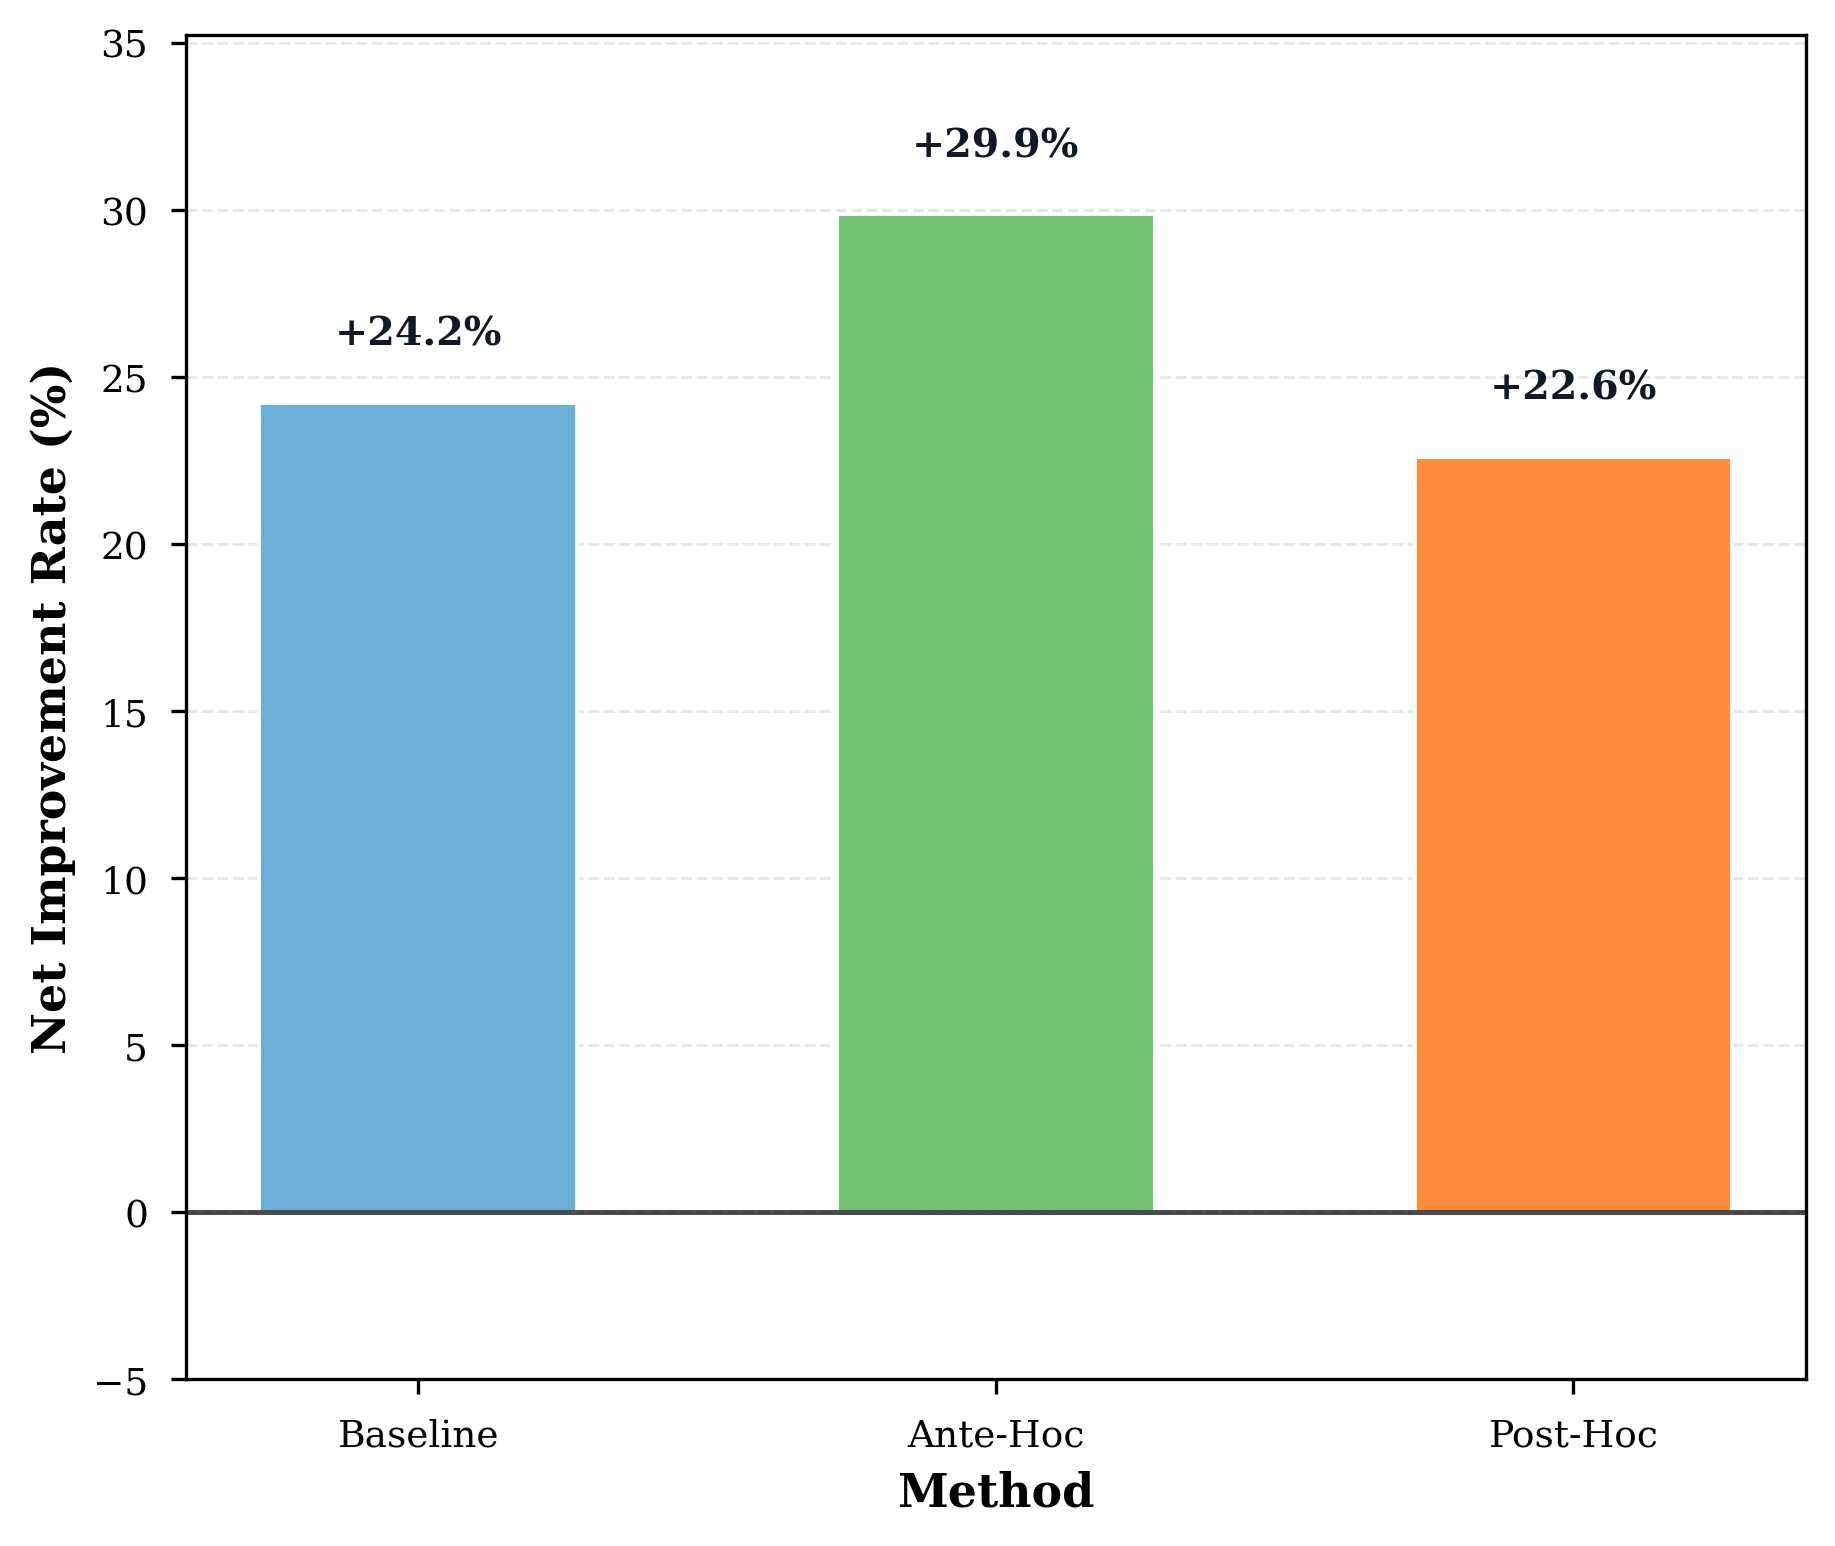

Compared to our study findings, we find similar performance in our toy example.

Effectively, patch performacne on our Baseline (PTC) method should be near identical to Post-Hoc (PTC_EXP), considering our generation step is the same.

However, what is interesting is that in both our study findings, as well as this toy example, there is a noticeable improvement in including explanation-based prompting within the provided prompt. Similar to Chain of Though reasoning, in directing the model to document and consider specific aspects of the patch generation process (and the aftermath that comes after) we see noticeable gains in patching performance and a reduction in positive Bandit detections.
